# Visualizing the training data and augmentations

This notebook shows exactly what the encoder will receive during training:

1. **Dataset facts**: frame interval, frame_gap, t1 window, z window.
2. **Raw biology**: a few timepoints of the full field of view (pre-augmentation).
3. **One positive pair**: view1 and view2 as the model actually sees them, plus the diff.
4. **Depth (z) montage**: the 3D-ness inside one crop.
5. **Augmentation variation**: 16 independent augmentations of the same crop.
6. **Per-augmentation isolation**: effect of each augmentation on its own.
7. **Crop-size context**: how much of the field one crop covers.
8. **One real batch**: what the DataLoader actually hands to the model.

Each cell is independent. Re-run cells after editing `cfg` to see the effect.

In [1]:
# setup: build cfg, pick zarr (or use multi-zarr from yaml), build dataset, define helpers.
import sys, os, time, copy
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from configs.config import Config
from data.dataset import ZarrCellDataset, MultiZarrDataset, worker_init_fn
from data.picker import pick_zarr_path
from data.augmentations import build_augmentations

# load defaults; swap for `Config.from_yaml('../configs/train.yaml')` to use the yaml.
cfg = Config.from_yaml("../configs/train.yaml")
# fresh seed per notebook run so each session sees different crops.
cfg.seed = time.time_ns() % (2**31 - 1)

# anchor any relative paths in the yaml to the project root so the notebook
# works regardless of where jupyter was launched from.
_project_root = os.path.abspath('..')
if not os.path.isabs(cfg.training_data_index_path):
    cfg.training_data_index_path = os.path.join(_project_root, cfg.training_data_index_path)

# build the right dataset shape.
if cfg.zarr_paths:
    ds = MultiZarrDataset(cfg)
    primary = ds.children[0]  # used for single-crop visualizations below
    is_multi = True
else:
    if cfg.zarr_path is None:
        cfg.zarr_path = pick_zarr_path()
    ds = ZarrCellDataset(cfg)
    primary = ds
    is_multi = False

sample_iter = iter(ds)

print('is_multi             :', is_multi)
print('seed                 :', cfg.seed)
print('crop_size            :', cfg.crop_size)
print('z_thickness          :', cfg.z_thickness)
print('target_gap_minutes   :', cfg.target_gap_minutes)
print('temporal_direction   :', cfg.temporal_direction)
print()
if is_multi:
    print(f'mixed across {len(ds.children)} datasets:')
    for i, c in enumerate(ds.children):
        print(f'  [{i}] {c.cfg.zarr_path}')
        print(f'      shape={tuple(c.arr.shape)} interval_min={c.interval_minutes} frame_gap={c.frame_gap}')
else:
    print('zarr_path            :', primary.cfg.zarr_path)
    print('arr.shape (T,C,Z,Y,X):', tuple(primary.arr.shape))
    print('interval_minutes     :', primary.interval_minutes)
    print('frame_gap (frames)   :', primary.frame_gap)
    print(f'wall-clock gap       : {primary.frame_gap * primary.interval_minutes:.1f} min')
    print('t1 window            :', (primary.t1_min, primary.t1_max))
    print('z window             :', (primary.z_min, primary.z_max))


# ----- visualization helpers -----

def mean_projection(volume):
    """average across z; gives a clean 2d view of a (z, h, w) volume."""
    return volume.mean(axis=0)


def mip(volume):
    """max projection across z; bright structures stand out."""
    return volume.max(axis=0)


def z_montage(volume, ncols=5):
    """tile z slices side by side into one image."""
    z, h, w = volume.shape
    nrows = (z + ncols - 1) // ncols
    out = np.zeros((nrows * h, ncols * w), dtype=volume.dtype)
    for i in range(z):
        r, c = divmod(i, ncols)
        out[r*h:(r+1)*h, c*w:(c+1)*w] = volume[i]
    return out


def percentile_limits(values, low=1.0, high=99.0):
    """display limits robust to a few bright outliers."""
    lo, hi = np.percentile(np.asarray(values), [low, high])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        lo, hi = float(np.min(values)), float(np.max(values))
    if hi <= lo:
        hi = lo + 1e-6
    return float(lo), float(hi)


def show_gray(ax, image, title, limits):
    ax.imshow(image, cmap='gray', vmin=limits[0], vmax=limits[1])
    ax.set_title(title, fontsize=10)
    ax.axis('off')


def raw_frame_mean(child, t, z0, z1):
    """full-frame mean projection in normalized [0, 1] intensity (pre-augmentation)."""
    vol = child.arr[int(t), child.cfg.channel, int(z0):int(z1), :, :].compute()
    vol = np.asarray(vol, dtype=np.float32)
    return (np.clip(vol, 0, child.cfg.max_intensity) / child.cfg.max_intensity).mean(axis=0)


[ZarrCellDataset] opened /Volumes/sgrolab/jennifer/cryolite/cryolite_mixin_test65_2024-04-16/NC28.1_overnight_day1/2024-04-16_ERH_mixin65_plate1_NC28.1_overnight_ERH Red FarRed.zarr shape=(145, 2, 179, 1907, 1443) chunks=((1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), (1, 1), (1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

## 1. Raw biology: the field of view over time

Full-frame mean projections at evenly-spaced timepoints, in normalized `[0, 1]` intensity (clip → divide by `max_intensity`). No augmentations, no cropping, this is what's *inside* the zarr.

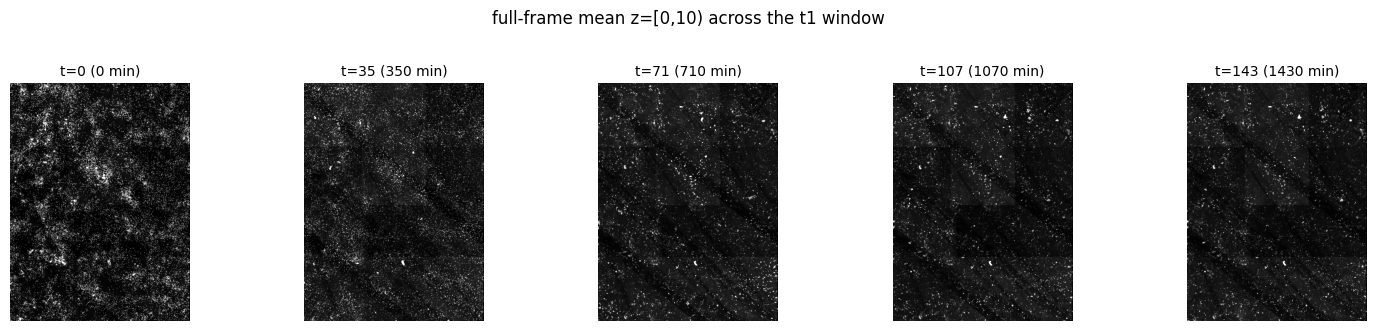

In [2]:
n_panels = 5
ts = np.linspace(primary.t1_min, primary.t1_max - 1, n_panels).astype(int)
z0 = primary.z_min
z1 = z0 + cfg.z_thickness

frames = [raw_frame_mean(primary, t, z0, z1) for t in ts]
lims = percentile_limits(np.concatenate([f.ravel() for f in frames]), 0.5, 99.5)

fig, axes = plt.subplots(1, n_panels, figsize=(3 * n_panels, 3.2))
for ax, f, t in zip(axes, frames, ts):
    mins = t * primary.interval_minutes
    show_gray(ax, f, f't={int(t)} ({mins:.0f} min)', lims)
plt.suptitle(f'full-frame mean z=[{z0},{z1}) across the t1 window', y=1.02)
plt.tight_layout(); plt.show()


## 2. A positive pair the model actually receives

The model never sees raw intensities. It sees the post-augmentation tensor.
With `aug_percrop_norm` enabled, each crop is z-scored (mean 0, std 1) before being handed off, so the visible intensities below are normalized units.

pair meta: {'t1': 118, 't2': 120, 'z': 88, 'z_end': 98, 'x': 1284, 'y': 284, 'dataset_idx': 1}
wall-clock gap: 20.0 min (2 frames)
view shape (1, z, h, w): (1, 10, 128, 128)


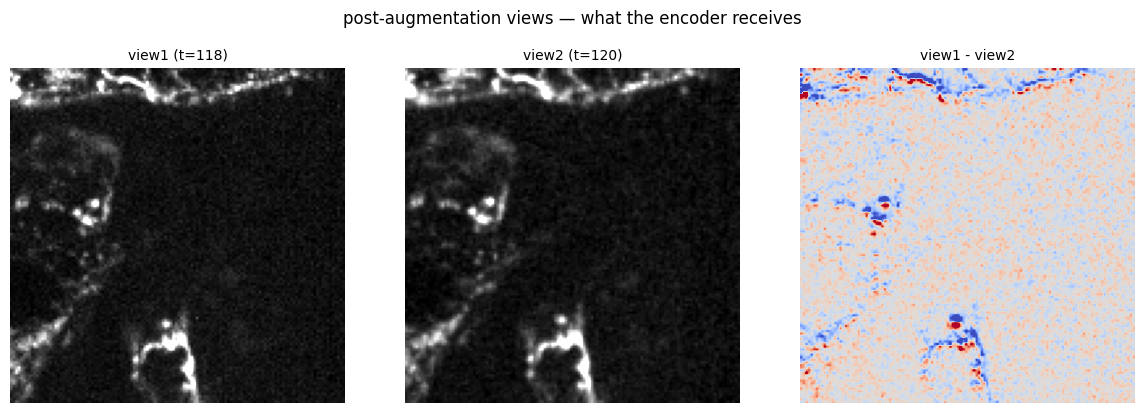

In [3]:
pair = next(sample_iter)
v1 = pair['view1'][0].numpy()
v2 = pair['view2'][0].numpy()
meta = pair['meta']

print('pair meta:', {k: int(v) if hasattr(v, '__int__') else v for k, v in meta.items()})
gap_frames = int(meta['t2']) - int(meta['t1'])
print(f'wall-clock gap: {gap_frames * primary.interval_minutes:.1f} min ({gap_frames} frames)')
print(f'view shape (1, z, h, w): {tuple(pair["view1"].shape)}')

v1_mp = mean_projection(v1)
v2_mp = mean_projection(v2)
diff = v1_mp - v2_mp
view_lims = percentile_limits(np.concatenate([v1_mp.ravel(), v2_mp.ravel()]), 1.0, 99.0)
diff_abs = float(np.percentile(np.abs(diff), 99.0)) or 1.0
diff_lims = (-diff_abs, diff_abs)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
show_gray(axes[0], v1_mp, f'view1 (t={int(meta["t1"])})', view_lims)
show_gray(axes[1], v2_mp, f'view2 (t={int(meta["t2"])})', view_lims)
axes[2].imshow(diff, cmap='coolwarm', vmin=diff_lims[0], vmax=diff_lims[1])
axes[2].set_title('view1 - view2', fontsize=10); axes[2].axis('off')
plt.suptitle('post-augmentation views — what the encoder receives', y=1.02)
plt.tight_layout(); plt.show()


## 3. Depth montage: what the z dimension looks like

The encoder receives a 3D tensor `(1, z_thickness, H, W)` per view. This montages the individual z slices of view1 so you can see what's stacked together.

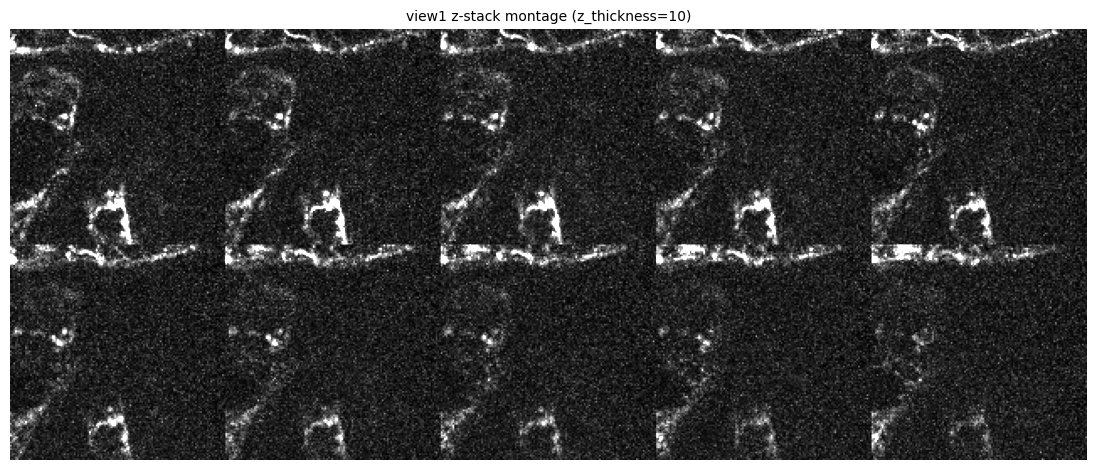

In [4]:
montage = z_montage(v1)
mlims = percentile_limits(v1, 1.0, 99.0)
fig, ax = plt.subplots(figsize=(12, 12 * (montage.shape[0] / montage.shape[1])))
show_gray(ax, montage, f'view1 z-stack montage (z_thickness={cfg.z_thickness})', mlims)
plt.tight_layout(); plt.show()


## 4. 16 independent augmentations of the same crop

Same anchor every time; only the augmentation roll changes. Use this to gauge whether augmentations are strong enough to corrupt surface noise but not so strong they destroy biology.

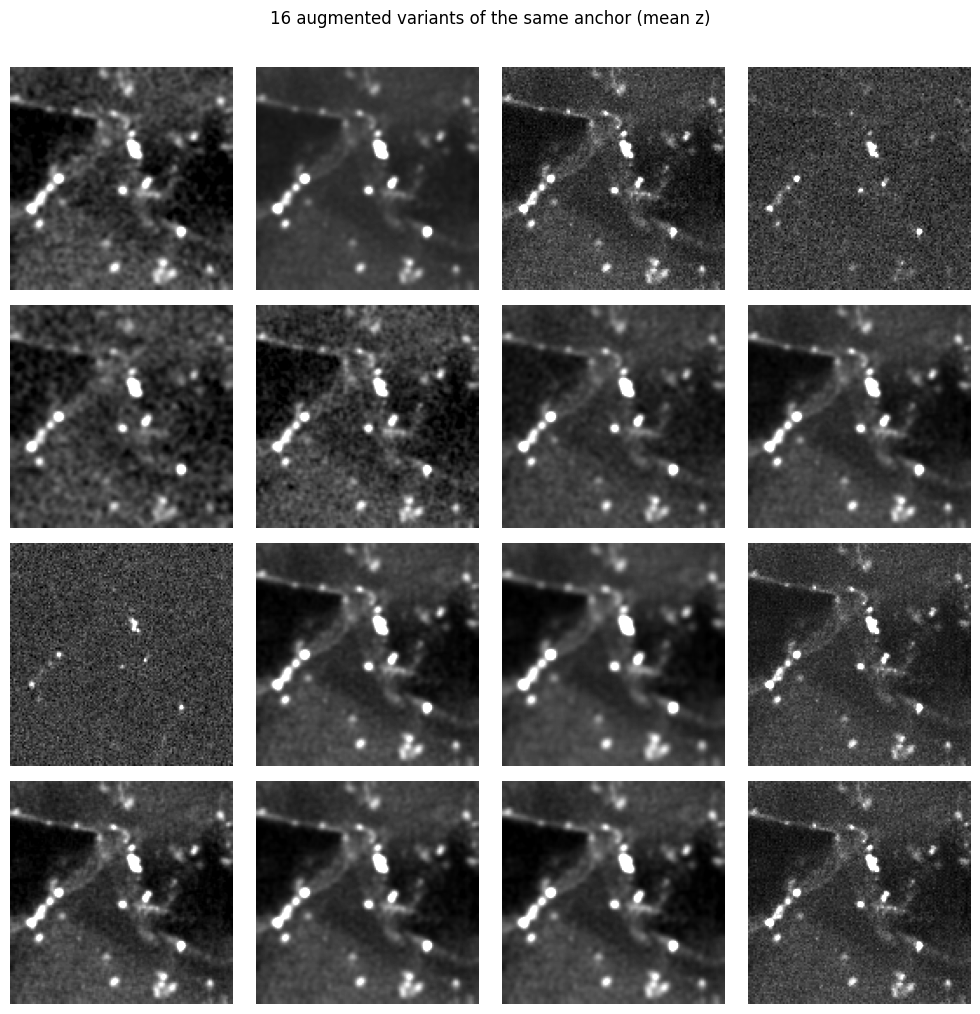

In [5]:
m = meta
base = primary._load_crop(int(m['t1']), int(m['z']), int(m['y']), int(m['x']),
                          cfg.crop_size, cfg.crop_size)
augment = build_augmentations(cfg)
samples = [mean_projection(augment(base.clone())[0].numpy()) for _ in range(16)]
lims = percentile_limits(np.concatenate([s.ravel() for s in samples]), 1.0, 99.0)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, img in zip(axes.flat, samples):
    show_gray(ax, img, '', lims)
plt.suptitle('16 augmented variants of the same anchor (mean z)', y=1.01)
plt.tight_layout(); plt.show()


## 5. Each augmentation in isolation

Same crop, but only one augmentation type is active at a time (and forced to `p=1.0`). `per-crop normalization` is always applied last so panels share a comparable scale.

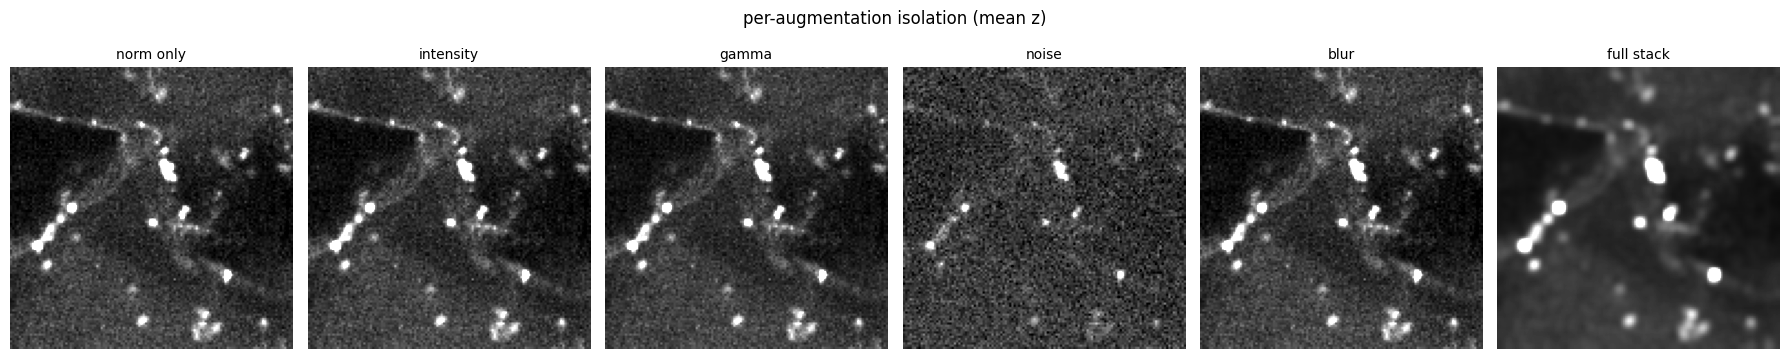

In [6]:
def isolate(name):
    c = copy.deepcopy(cfg)
    for attr in ('aug_intensity', 'aug_gamma', 'aug_noise', 'aug_blur'):
        getattr(c, attr).enabled = (attr == name)
        if attr == name:
            getattr(c, attr).p = 1.0
    c.aug_percrop_norm.enabled = True
    return build_augmentations(c)

def norm_only():
    c = copy.deepcopy(cfg)
    for attr in ('aug_intensity', 'aug_gamma', 'aug_noise', 'aug_blur'):
        getattr(c, attr).enabled = False
    return build_augmentations(c)

modes = [
    ('norm only',  norm_only()),
    ('intensity',  isolate('aug_intensity')),
    ('gamma',      isolate('aug_gamma')),
    ('noise',      isolate('aug_noise')),
    ('blur',       isolate('aug_blur')),
    ('full stack', build_augmentations(cfg)),
]
imgs = [(name, mean_projection(aug(base.clone())[0].numpy())) for name, aug in modes]
lims = percentile_limits(np.concatenate([img.ravel() for _, img in imgs]), 1.0, 99.0)

fig, axes = plt.subplots(1, len(modes), figsize=(3 * len(modes), 3.5))
for ax, (name, img) in zip(axes, imgs):
    show_gray(ax, img, name, lims)
plt.suptitle('per-augmentation isolation (mean z)', y=1.02)
plt.tight_layout(); plt.show()


## 6. Crop-size context

The encoder sees a `crop_size × crop_size` window from a much larger frame. I overlayed a few candidate sizes on the current anchor so you can see how much of the biological field one crop covers.

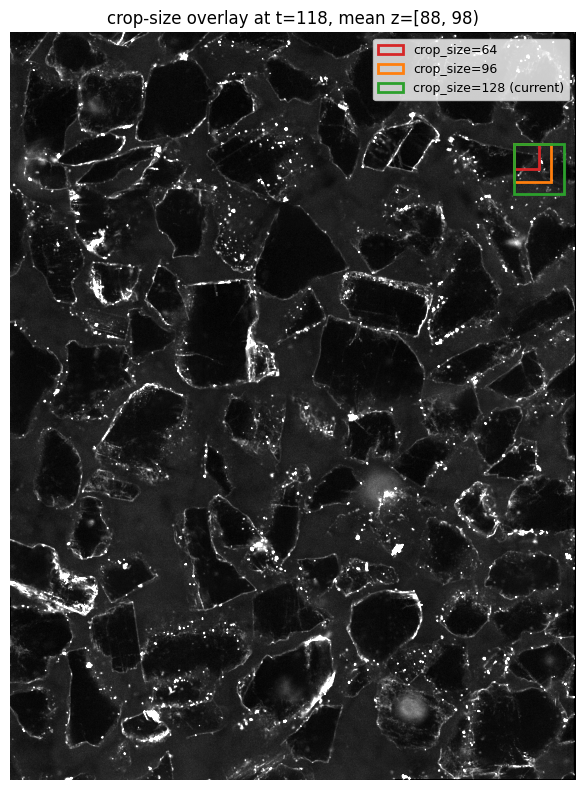

In [7]:
z0 = int(meta['z']); z1 = z0 + cfg.z_thickness
frame = raw_frame_mean(primary, int(meta['t1']), z0, z1)
flims = percentile_limits(frame, 0.5, 99.0)

sizes = sorted({64, 96, cfg.crop_size, 224, 320})
colors = ['tab:red', 'tab:orange', 'tab:green', 'tab:blue', 'tab:purple']
x_off, y_off = int(meta['x']), int(meta['y'])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(frame, cmap='gray', vmin=flims[0], vmax=flims[1])
for s, c in zip(sizes, colors):
    if y_off + s > frame.shape[0] or x_off + s > frame.shape[1]:
        continue
    label = f'crop_size={s}' + (' (current)' if s == cfg.crop_size else '')
    rect = patches.Rectangle((x_off, y_off), s, s,
                             linewidth=2, edgecolor=c, facecolor='none', label=label)
    ax.add_patch(rect)
ax.legend(loc='upper right', fontsize=9)
ax.set_title(f'crop-size overlay at t={int(meta["t1"])}, mean z=[{z0}, {z1})')
ax.axis('off')
plt.tight_layout(); plt.show()


## 7. A full batch as the DataLoader hands it to the model

This pulls the first batch the DataLoader would emit. Each row is one pair (view1 | view2), in normalized units, post-augmentation. If running on a `MultiZarrDataset`, each row is tagged with `ds=N` so you can see how a single batch mixes experiments.

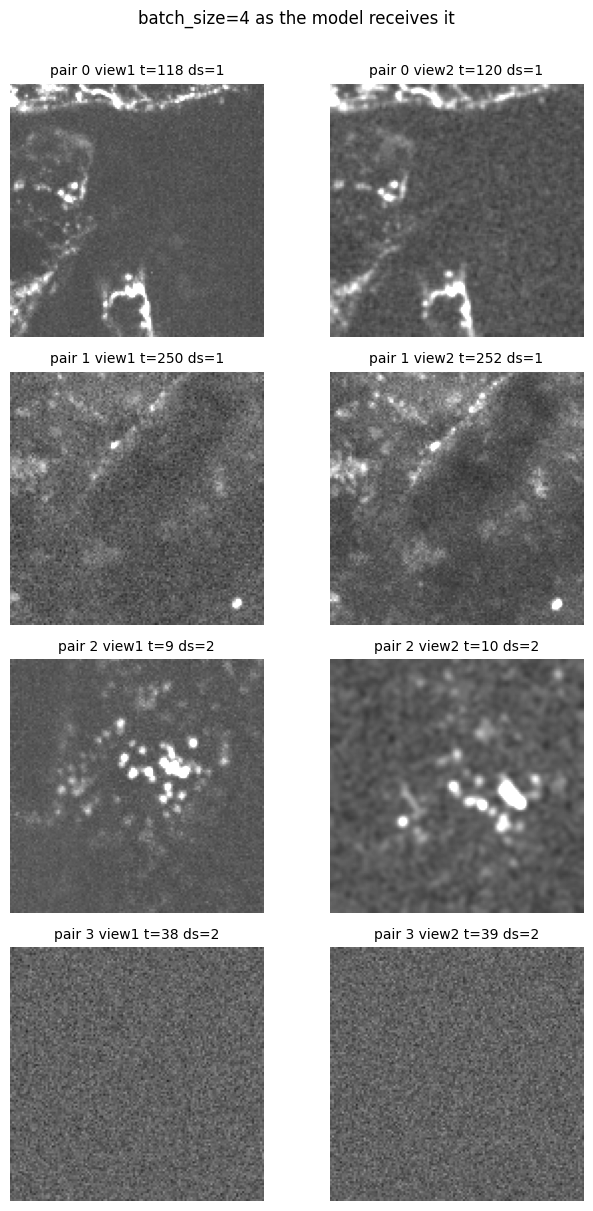

In [8]:
from torch.utils.data import DataLoader

batch_size = 4
loader = DataLoader(
    ds,
    batch_size=batch_size,
    num_workers=0,  # in-process so the notebook stays simple
    worker_init_fn=worker_init_fn,
)

batch = next(iter(loader))
v1s = batch['view1'].numpy()
v2s = batch['view2'].numpy()
metas = batch['meta']

# shared display limits across the whole batch.
pool = np.concatenate([v1s.ravel(), v2s.ravel()])
lims = percentile_limits(pool, 1.0, 99.0)

fig, axes = plt.subplots(batch_size, 2, figsize=(7, 3.0 * batch_size))
for i in range(batch_size):
    label_extra = ''
    if is_multi and 'dataset_idx' in metas:
        label_extra = f' ds={int(metas["dataset_idx"][i])}'
    t1, t2 = int(metas['t1'][i]), int(metas['t2'][i])
    show_gray(axes[i, 0], mean_projection(v1s[i, 0]),
              f'pair {i} view1 t={t1}{label_extra}', lims)
    show_gray(axes[i, 1], mean_projection(v2s[i, 0]),
              f'pair {i} view2 t={t2}{label_extra}', lims)
plt.suptitle(f'batch_size={batch_size} as the model receives it', y=1.005)
plt.tight_layout(); plt.show()
